# Anguish – Ice (Harakim)

Anguish (Ice) is a single-target debuff that lowers the target's armor and weapon value by the
same amount for 20 s.

**Rebalanced.** The drop was `clamp(p/8, 2, 30)`, which hit its −30 ceiling at modified skill
240, short of what top-rank players reach (275–300). It now uses `skill_knee_300(p, 0, 30)`
(`anguish_ice_drop`): −1 per 10 skill points up to −30 at skill 300, then −1 per 20 points up to
a hard limit of −45 at skill 600. The floor of −2 is unchanged. The dotted "before" curves below
show the old `p/8` formula.

| | |
|---|---|
| Class | Harakim |
| Target | Single hostile |
| Cost | 35 mana (the skill description says 30), spent before the roll |
| Cooldown | none: Anguish adds no exhaust (it is refused while exhausted) |
| Landing roll | `chance_base(skill, 10, effective_resist(Resist))` |
| Duration | 20 s |
| Effect | `armor[1]` and `weapon[1]` += $-\operatorname{clamp}(\text{skill\_knee\_300}(p, 0, 30),\ 2,\ 45)$; the final values are clamped at 0 |
| Source | `server/src/driver/skill/harakim.rs::anguish_ice_drop`, `skill_anguish_ice`, `anguish_preflight`, `attach_anguish`; curve in `server/src/driver/skill/common.rs::skill_knee_300`; clamp in `server/src/state/stats.rs` |

---

# Formula

With $p$ the raw modified skill (no Immunity reduction, negative treated as 0):

$$
d = \operatorname{clamp}\!\left(\begin{cases}
\left\lfloor \tfrac{30p}{300} \right\rfloor & p \le 300 \\[4pt]
30 + \left\lfloor \tfrac{30(p - 300)}{600} \right\rfloor & p > 300
\end{cases},\ 2,\ 45\right)
\qquad
\text{armor}' = \max(0,\ \text{armor} - d)
\qquad
\text{weapon}' = \max(0,\ \text{weapon} - d)
$$

Each point of armor removed adds 0.25 HP to every landed melee hit on the target and 0.75 HP to
every spell hit (`do_hurt` type 1). Each point of weapon removed takes 0.25 HP off every hit the
target lands, before the defender's armor.

| Quantity | Now | Before |
|---|---|---|
| Floor | −2 for $p \le 29$ | −2 for $p < 24$ |
| Slope to 300 | −1 per 10 skill points | −1 per 8 to skill 240 |
| Raise cap ($p$ 105 / 120) | −10 / −12 | −13 / −15 |
| Endgame ($p$ 275 / 300) | −27 / −30 | −30 |
| Beyond 300 | −1 per 20 (−32 at 350, −37 at 450) | −30 |
| Hard limit | −45 from $p \ge 600$ | −30 from $p \ge 240$ |
| Uptime | 35 mana per 20 s; a same-power recast refreshes it | same |

---

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import mag_model as mm

mm.apply_style()
P = mm.SKILL_RANGE
COST = 35
DURATION_S = 20

# Model

In [2]:
MAX_DROP = 45


def drop(p):
    return mm.clamp(mm.knee_300(p, 0, 30), 2, MAX_DROP)


# Before the mod-300 knee: -1 per 8 points, capped at -30 from skill 240.
def old_drop(p):
    return mm.clamp(mm.idiv(p, 8), 2, 30)


def ally_melee_gain(p, target_armor, wv=40, strength=80, drop=drop):
    """× damage per landed melee hit an ally deals to the debuffed target."""
    base = mm.melee_hit_hp(wv, strength, target_armor)
    after = mm.melee_hit_hp(wv, strength, np.maximum(0, target_armor - drop(p)))
    return np.where(base > 0, after / np.maximum(base, 1e-9), np.nan)


def target_melee_loss(p, target_wv, strength=80, defender_armor=20, drop=drop):
    """Fraction of the debuffed target's damage per landed hit that is removed."""
    base = mm.melee_hit_hp(target_wv, strength, defender_armor)
    if base <= 0:
        return np.full(np.shape(p), np.nan)
    after = np.array([mm.melee_hit_hp(max(0, target_wv - int(d)), strength, defender_armor)
                      for d in np.atleast_1d(drop(p))])
    out = 1 - after / base
    return out if np.ndim(p) else out[0]

# Validation

- `anguish_ice_lowers_armor_and_weapon`: skill 80 → mana 100,000 → 65,000 per attempt, armor and
  weapon −8, the item lasts `TICKS*20` and records the caster.
- `anguish_ice_modifiers_have_a_floor`: skill 8 → −2.
- `anguish_ice_drop_scales_to_skill_300_then_half_slope`: 0 → 2, 105 → 10, 300 → 30, 350 → 32,
  600 and 2000 → 45.

In [3]:
assert 100_000 - COST * 1000 == 65_000 and mm.TICKS * DURATION_S == 720
assert drop(80) == 8 and drop(8) == 2 and drop(0) == 2
assert [int(drop(p)) for p in (105, 300, 350, 600, 2000)] == [10, 30, 32, 45, 45]
assert [int(drop(p)) for p in (29, 30, 120, 275, 450)] == [2, 3, 12, 27, 37]
assert old_drop(105) == 13 and old_drop(120) == 15 and old_drop(240) == 30 and old_drop(800) == 30
print("Anguish-Ice model OK")

Anguish-Ice model OK


# Plots

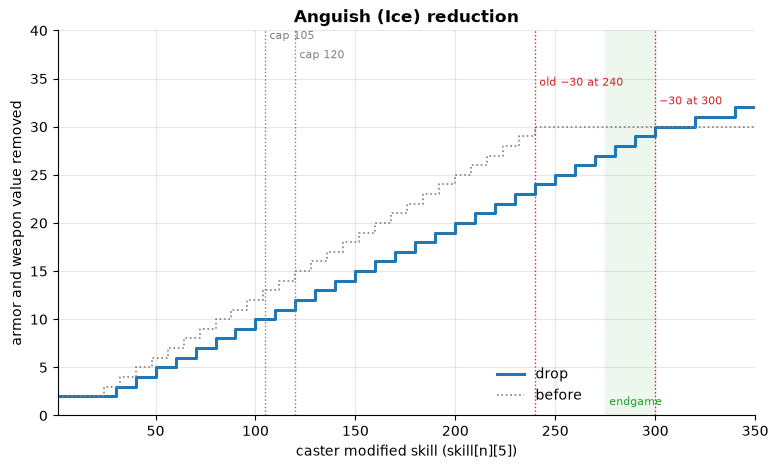

In [4]:
fig, ax = plt.subplots()
ax.step(P, drop(P), where="post", lw=2.2, label="drop")
ax.step(P, old_drop(P), where="post", color="grey", lw=1.2, ls=":", label="before")
mm.skill_axis(ax, "armor and weapon value removed", "Anguish (Ice) reduction")
ax.set_ylim(0, 40)
mm.mark_caps(ax, extra=[(240, "old −30 at 240"), (mm.SKILL_KNEE, "−30 at 300")])
ax.legend(loc="lower right", bbox_to_anchor=(0.77, 0))

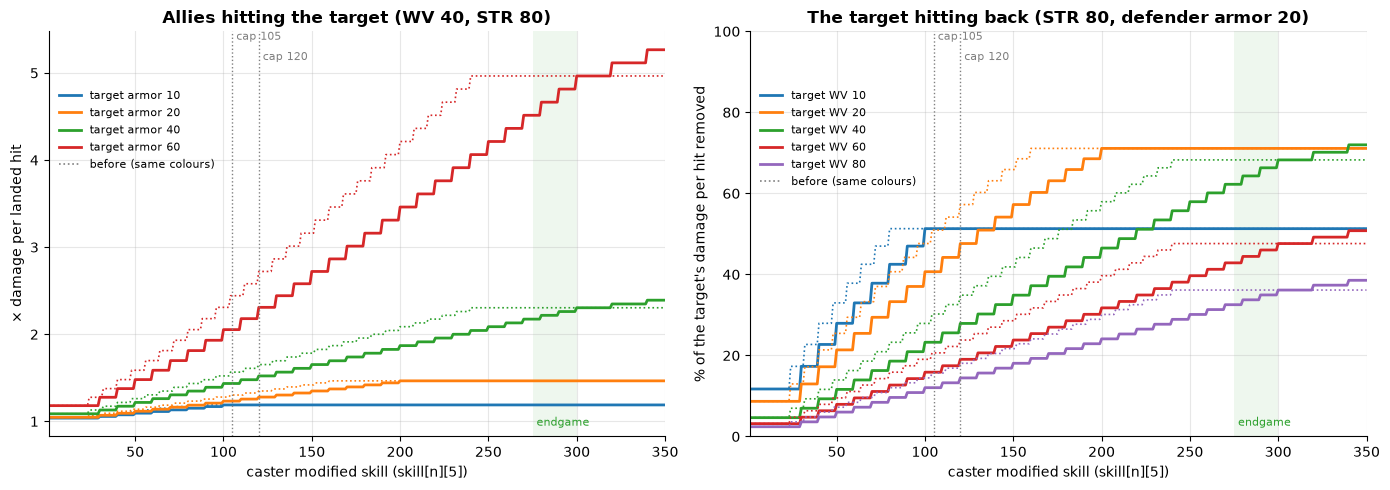

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = ("tab:blue", "tab:orange", "tab:green", "tab:red", "tab:purple")

ax = axes[0]
for c, armor in zip(colors, (10, 20, 40, 60)):
    ax.plot(P, ally_melee_gain(P, armor), color=c, label=f"target armor {armor}")
    ax.plot(P, ally_melee_gain(P, armor, drop=old_drop), color=c, lw=1.2, ls=":")
ax.plot([], [], color="grey", lw=1.2, ls=":", label="before (same colours)")
mm.skill_axis(ax, "× damage per landed hit", "Allies hitting the target (WV 40, STR 80)")
mm.mark_caps(ax)
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.88), fontsize=8)

ax = axes[1]
for c, wv in zip(colors, mm.WV_SWEEP):
    ax.plot(P, 100 * target_melee_loss(P, wv), color=c, label=f"target WV {wv}")
    ax.plot(P, 100 * target_melee_loss(P, wv, drop=old_drop), color=c, lw=1.2, ls=":")
ax.plot([], [], color="grey", lw=1.2, ls=":", label="before (same colours)")
mm.skill_axis(ax, "% of the target's damage per hit removed", "The target hitting back (STR 80, defender armor 20)")
ax.set_ylim(0, 100)
mm.mark_caps(ax)
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.88), fontsize=8)
plt.tight_layout()

# Observations

- The drop reaches −30 at modified skill 300 instead of 240. At the endgame (275–300) it is −27
  to −30, the same as the old ceiling at 300. Skill from gear keeps paying: −32 at 350, −37 at
  450 and −45 at 600, where it stops.
- The mid-game is weaker. At the raise cap of 105 the drop is −10 (before −13), and −12 at 120
  (before −15). The new curve is at or below the old one everywhere up to skill 310 and passes
  it from 320.
- At skill 105 a WV-40 STR-80 ally deals ×1.23 per landed hit against armor 20 (10.75 → 13.25 HP,
  before ×1.30) and ×1.43 against armor 40 (5.75 → 8.25, before ×1.57). Armor 20 is gone entirely
  from skill 200 (×1.47), and at 300 armor 40 gives ×2.30. The gain grows with the target's armor, because a
  fixed drop is a larger share of a small post-armor remainder.
- Against a defender with armor 20, at skill 105 the target loses 41% of its damage per hit at
  WV 20, 23% at WV 40 and 12% at WV 80 (before 51%, 30% and 16%). At 300 the losses are 71%, 68%
  and 36%.
- Spell hits gain 0.75 HP per armor point, so a Blast hit gains 7.5 HP at skill 105 (about 5% of
  the 142.5 HP a plain Blast deals to armor 20) and 22.5 HP at 300. Lava burns and the Ice Stun
  shatter ignore armor anyway. Anguish (Ice) is a support spell for melee allies.
- No talent node or other code path in `core/` or `server/` grants `SK_ANGUISH_ICE`, the same as
  Anguish (Lava). "Elemental Anguish" teaches only Anguish (Earth).
- Anguish adds no exhaust and does not record an element, so it does not trigger Element
  Switching. With a 20 s duration, keeping it up costs 35 mana per 20 s against the d20-10 roll.
- The description lists 30 mana; the code charges 35.
- Fix the description, grant the skill somewhere in the tree, and consider letting it count as an
  ice cast for Element Switching.